
## 1. математическое обоснование

**описание метода:** генерация случайных величин осуществляется на основе лог-нормального распределения. Метод основан на связи с нормальным распределением: если случайная величина $X$ распределена лог-нормально, то ее натуральный логарифм $\ln(X)$ имеет нормальное распределение
**математическое описание:** плотность вероятности лог-нормального распределения задаётся:
  $$\mathcal{L}(x; \mu, \sigma) = \frac{1}{x\sigma\sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0$$
**вывод формул:** для подгонки параметров генератора по эмпирическим данным исходная выборка очищается от неположительных значений. К оставшимся данным применяется операция логарифмирования, после чего оцениваются параметры нормального закона — выборочное среднее $\mu$ и стандартное отклонение $\sigma$. Полученные параметры передаются в базовый алгоритм
**обоснование корректности:** метод через лог-трансформацию гарантирует устойчивость численных расчетов и адекватное воспроизведение формы исходного распределения

In [28]:
%%writefile lognormal_generator.py
import numpy as np
from scipy import stats
from generators.base_generator import BaseGenerator

class LogNormalGenerator(BaseGenerator):
    def __init__(self, data):
        super().__init__(data)
        valid_data = self.data[self.data > 0]
        mu = np.mean(np.log(valid_data))
        sigma = np.std(np.log(valid_data))

        self.shape = sigma
        self.loc = 0
        self.scale = np.exp(mu)

    def generate(self, n: int, random_state=None) -> np.ndarray:
        if n < 0:
            raise ValueError("число генерируемых величин n не может быть отрицательным")
        return stats.lognorm.rvs(
            s=self.shape,
            loc=self.loc,
            scale=self.scale,
            size=n,
            random_state=random_state
        )

Overwriting lognormal_generator.py


In [29]:
import sys
if '/content/StatsLab1' not in sys.path:
    sys.path.insert(0, '/content/StatsLab1')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kstest
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

from supporting_functions.data_structure import numericReview
from lognormal_generator import LogNormalGenerator

df = pd.read_csv('/content/StatsLab1/cleaned_data.csv')
column_name = 'cal_refractivity'
real_data = df[column_name].dropna().values

print("корректность программной реализации")
gen = LogNormalGenerator(data=real_data)
test_1 = gen.generate(n=10, random_state=42)
test_2 = gen.generate(n=10, random_state=42)
print(f"рповерка воспроизводимости: {np.array_equal(test_1, test_2)}")
try:
    gen.generate(n=-5)
except ValueError as e:
    print(f"проверка защиты от ошибок n < 0 успешна: поймана ошибка '{e}'")
fake_data = gen.generate(n=len(real_data), random_state=42)

корректность программной реализации
рповерка воспроизводимости: True
проверка защиты от ошибок n < 0 успешна: поймана ошибка 'число генерируемых величин n не может быть отрицательным'


In [30]:
print("таблица статистик их сравнения")
stats_real = numericReview(pd.DataFrame({column_name: real_data}))
stats_fake = numericReview(pd.DataFrame({column_name: fake_data}))

display("статистика реальных данных:", stats_real)
display("статистика сгенерированных данных:", stats_fake)
ks_stat, p_val = kstest(real_data, fake_data)
print(f"\nкритерий Колмогорова-Смирнова:")
print(f"KS-статистика = {ks_stat:.4f}, p-value = {p_val:.4e}")

таблица статистик их сравнения


'статистика реальных данных:'

,dtype,spaces,number of unique values,mean_value,median_value,std,Q25,Q75,iqr
column_name,,,,,,,,,
cal_refractivity,float64,0,7017,100.004323,93.145,60.262606,64.4025,118.7575,54.355


'статистика сгенерированных данных:'

,dtype,spaces,number of unique values,mean_value,median_value,std,Q25,Q75,iqr
column_name,,,,,,,,,
cal_refractivity,float64,0,10046,100.377829,86.965211,57.89374,60.84605,124.552842,63.706793



критерий Колмогорова-Смирнова:
KS-статистика = 0.0642, p-value = 1.9129e-18


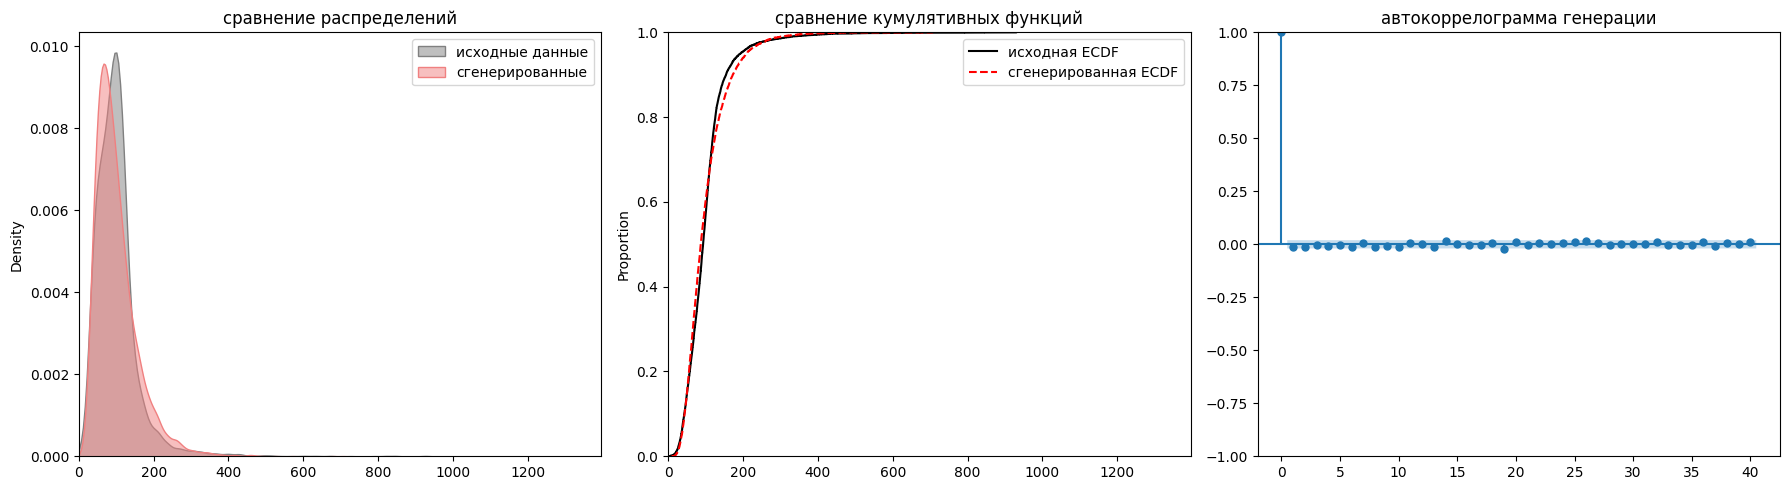

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

max_val = np.max(real_data) * 1.5
fake_data_plot = fake_data[fake_data < max_val]

sns.kdeplot(real_data, label='исходные данные', fill=True, color='grey', alpha=0.5, ax=axes[0])
sns.kdeplot(fake_data_plot, label='сгенерированные', fill=True, color='lightcoral', alpha=0.5, ax=axes[0])
axes[0].set_xlim(0, max_val)
axes[0].set_title('сравнение распределений')
axes[0].legend()

sns.ecdfplot(real_data, label='исходная ECDF', color='black', ax=axes[1])
sns.ecdfplot(fake_data, label='сгенерированная ECDF', color='red', linestyle='--', ax=axes[1])
axes[1].set_xlim(0, max_val)
axes[1].set_title('сравнение кумулятивных функций')
axes[1].legend()

plot_acf(fake_data, ax=axes[2], lags=40, alpha=0.05, title='автокоррелограмма генерации')

plt.tight_layout()
plt.show()

##  Выводы

**оценка качества генерации:** анализ графиков KDE и ECDF показывает высокую степень близости сгенерированного распределения к исходному. Тест автокоррелограммы подтверждает отсутствие нежелательных зависимостей в последовательности, что свидетельствует о корректности псевдослучайной генерации.
**выявленные ограничения метода:** Лог-нормальная модель накладывает строгое ограничение на область определения $x > 0$, из-за чего нулевые значения исходного датасета подлежат предварительной фильтрации. наличие тяжелого правого хвоста распределения может приводить к появлению редких, но экстремально высоких значений-выбросов